In [2]:
# # ================================
# # STEP 1: Import Libraries
# # ================================
# import pandas as pd
# import numpy as np

# from sklearn.model_selection import train_test_split
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     classification_report,
#     confusion_matrix
# )

# import matplotlib.pyplot as plt
# import seaborn as sns


# # ================================
# # STEP 2: Load Dataset
# # ================================
# df = pd.read_csv("../dataset/insider_threat_clean_dataset.csv")

# # Reduce dataset size for faster training
# df = df.sample(30000, random_state=42)

# # ================================
# # STEP 3: Basic Data Checks
# # ================================
# print("First 5 Rows:")
# print(df.head())

# print("\nMissing Values:")
# print(df.isnull().sum())

# print("\nDuplicate Rows:", df.duplicated().sum())


# # Remove duplicates if any
# df = df.drop_duplicates()


# # ================================
# # STEP 4: Separate Features and Target
# # ================================
# X = df.drop("is_malicious", axis=1)
# y = df["is_malicious"]


# # ================================
# # STEP 5: Encode Categorical Columns
# # ================================
# X = pd.get_dummies(X)


# # ================================
# # STEP 6: Train Test Split
# # ================================
# X_train, X_test, y_train, y_test = train_test_split(
#     X,
#     y,
#     test_size=0.2,
#     random_state=42
# )


# # ================================
# # STEP 7: Train Improved Random Forest Model
# # ================================
# model = RandomForestClassifier(
#     n_estimators=50,
#     max_depth=10,
#     min_samples_split=5,
#     min_samples_leaf=2,
#     class_weight="balanced",
#     random_state=42
# )

# model.fit(X_train, y_train)


# # ================================
# # STEP 8: Predictions
# # ================================
# predictions = model.predict(X_test)


# # ================================
# # STEP 9: Evaluation Metrics
# # ================================
# print("\nMODEL PERFORMANCE")
# print("--------------------")

# print("Accuracy:", accuracy_score(y_test, predictions))
# print("Precision:", precision_score(y_test, predictions))
# print("Recall:", recall_score(y_test, predictions))
# print("F1 Score:", f1_score(y_test, predictions))

# print("\nClassification Report:")
# print(classification_report(y_test, predictions))


# # ================================
# # STEP 10: Confusion Matrix
# # ================================
# cm = confusion_matrix(y_test, predictions)

# plt.figure(figsize=(6,4))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
# plt.xlabel("Predicted")
# plt.ylabel("Actual")
# plt.title("Confusion Matrix")
# plt.show()


# # ================================
# # STEP 11: Actual vs Predicted Table
# # ================================
# comparison_df = pd.DataFrame({
#     "Actual": y_test,
#     "Predicted": predictions
# })

# comparison_df["Actual"] = comparison_df["Actual"].map({
#     0: "Normal",
#     1: "Suspicious"
# })

# comparison_df["Predicted"] = comparison_df["Predicted"].map({
#     0: "Normal",
#     1: "Suspicious"
# })

# print("\nActual vs Predicted:")
# print(comparison_df.head(20))


# # ================================
# # STEP 12: Risk Score / Probability
# # ================================
# probabilities = model.predict_proba(X_test)

# risk_score = probabilities[0][1] * 100


# # ================================
# # STEP 13: Threat Level Logic
# # ================================
# if risk_score <= 40:
#     threat_level = "Low"
# elif risk_score <= 70:
#     threat_level = "Medium"
# else:
#     threat_level = "High"


# prediction_text = "Suspicious" if predictions[0] == 1 else "Normal"


# print("\nFINAL OUTPUT")
# print("--------------------")
# print("Employee/Test Row ID:", X_test.index[0])
# print("Prediction:", prediction_text)
# print("Risk Score:", round(risk_score, 2), "%")
# print("Threat Level:", threat_level)


# # ================================
# # STEP 14: Feature Importance
# # ================================
# # importance = pd.Series(
# #     model.feature_importances_,
# #     index=X.columns
# # ).sort_values(ascending=False)

# # print("\nTop 10 Important Features:")
# # print(importance.head(10))


# # plt.figure(figsize=(10,5))
# # importance.head(10).plot(kind='bar')
# # plt.title("Top 10 Important Features")
# # plt.show()

In [3]:
# import pandas as pd
# import numpy as np

# from sklearn.model_selection import train_test_split
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score
# )

# # ==========================================
# # LOAD DATASET
# # ==========================================
# df = pd.read_csv("../dataset/insider_threat_clean_dataset.csv")

# # ==========================================
# # SHOW ORIGINAL DATASET SIZE
# # ==========================================
# print("ORIGINAL DATASET SHAPE")
# print("----------------------")
# print("Rows:", df.shape[0])
# print("Columns:", df.shape[1])

# # ==========================================
# # REDUCE DATASET TO 50K ROWS
# # ==========================================
# df = df.sample(50000, random_state=42)

# print("\nREDUCED DATASET SHAPE")
# print("----------------------")
# print("Rows:", df.shape[0])
# print("Columns:", df.shape[1])

# # ==========================================
# # SEPARATE FEATURES AND TARGET
# # ==========================================
# y = df["is_malicious"]

# X = df.drop("is_malicious", axis=1)

# # ==========================================
# # CONVERT CATEGORICAL DATA TO DUMMY VARIABLES
# # ==========================================
# X = pd.get_dummies(X, drop_first=True)

# # Convert bool to int if generated
# X = X.astype(int)

# # ==========================================
# # SPLIT INTO TRAIN + REMAINING
# # ==========================================
# X_train, X_remaining, y_train, y_remaining = train_test_split(
#     X,
#     y,
#     test_size=0.30,
#     random_state=42
# )

# # ==========================================
# # LAST 20 ROWS FOR FORECAST
# # ==========================================
# X_test = X_remaining.iloc[:-20]
# y_test = y_remaining.iloc[:-20]

# X_forecast = X_remaining.iloc[-20:]
# y_forecast = y_remaining.iloc[-20:]

# # ==========================================
# # TRAIN MODEL
# # ==========================================
# model = RandomForestClassifier(
#     n_estimators=100,
#     random_state=42
# )

# model.fit(X_train, y_train)

# # ==========================================
# # TEST MODEL
# # ==========================================
# y_pred = model.predict(X_test)

# # ==========================================
# # EVALUATION METRICS
# # ==========================================
# print("\nMODEL PERFORMANCE")
# print("------------------")
# print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
# print("Precision:", round(precision_score(y_test, y_pred), 4))
# print("Recall   :", round(recall_score(y_test, y_pred), 4))
# print("F1 Score :", round(f1_score(y_test, y_pred), 4))

# # ==========================================
# # ACTUAL VS PREDICTED
# # ==========================================
# comparison = pd.DataFrame({
#     "Actual": y_test.values,
#     "Predicted": y_pred
# })

# print("\nACTUAL VS PREDICTED")
# print("------------------")
# print(comparison.head(20))

# # ==========================================
# # FORECAST NEXT 20 EMPLOYEES
# # ==========================================
# forecast_predictions = model.predict(X_forecast)
# forecast_prob = model.predict_proba(X_forecast)

# print("\nFINAL MODEL OUTPUT")
# print("-------------------")

# for i in range(len(X_forecast)):

#     prediction_text = (
#         "Malicious"
#         if forecast_predictions[i] == 1
#         else "Not Malicious"
#     )

#     risk_score = forecast_prob[i][1] * 100

#     if risk_score >= 80:
#         threat_level = "HIGH"
#     elif risk_score >= 50:
#         threat_level = "MEDIUM"
#     else:
#         threat_level = "LOW"

#     print("\nEmployee ID/Test Row:", X_forecast.index[i])
#     print("Prediction:", prediction_text)
#     print("Risk Score:", round(risk_score, 2), "%")
#     print("Threat Level:", threat_level)

In [4]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# LOAD TRAINING DATA
df = pd.read_csv("../dataset/augmented_insider_threat_dataset.csv")

print("Original Dataset Shape:", df.shape)

# Reduce size
df = df.sample(80000, random_state=42)

print("Reduced Dataset Shape:", df.shape)
# ADD THIS HERE
print("\nClass Distribution:")
print(df["is_malicious"].value_counts())

# Separate features and target
y = df["is_malicious"]
X = df.drop("is_malicious", axis=1)

# Dummy encoding
X = pd.get_dummies(X, drop_first=True)

# Save training columns for future uploaded data alignment
training_columns = X.columns

# Suspicious printing ratio
df["off_hour_print_ratio"] = (
    df["num_printed_pages_off_hours"] /
    (df["total_printed_pages"] + 1)
)

# Suspicious burning ratio
df["burn_ratio"] = (
    df["total_files_burned"] /
    (df["num_entries"] + 1)
)

# Mobility score
df["mobility_risk"] = (
    df["num_unique_campus"] *
    df["is_abroad"]
)

# Insider threat activity score
df["behavior_risk_score"] = (
    df["late_exit_flag"] +
    df["entry_during_weekend"] +
    df["burned_from_other"] +
    df["has_criminal_record"]
)

# High access anomaly
df["access_frequency_score"] = (
    df["num_entries"] /
    (df["trip_day_number"] + 1)
)

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train model
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced',
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5
)
model.fit(X_train, y_train)

joblib.dump(model, "malicious_detector.pkl")
joblib.dump(training_columns, "training_columns.pkl")

# Test predictions
y_pred = model.predict(X_test)

# Metrics
print("\nMODEL PERFORMANCE")
print("----------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred),4))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall   :", round(recall_score(y_test, y_pred),4))
print("F1 Score :", round(f1_score(y_test, y_pred),4))

# ADD THIS HERE
from sklearn.metrics import confusion_matrix

print("\nCONFUSION MATRIX")
print("----------------")
print(confusion_matrix(y_test, y_pred))

# Actual vs Predicted
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("\nACTUAL VS PREDICTED")
print(comparison.head(20))

train_pred = model.predict(X_train)

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy :", accuracy_score(y_test, y_pred))

Original Dataset Shape: (160325, 22)
Reduced Dataset Shape: (80000, 22)

Class Distribution:
is_malicious
0    55883
1    24117
Name: count, dtype: int64

MODEL PERFORMANCE
----------------
Accuracy : 0.9634
Precision: 0.9519
Recall   : 0.9257
F1 Score : 0.9386

CONFUSION MATRIX
----------------
[[10940   226]
 [  359  4475]]

ACTUAL VS PREDICTED
    Actual  Predicted
0        0          1
1        0          1
2        0          0
3        1          1
4        0          1
5        1          1
6        0          1
7        0          0
8        0          0
9        0          0
10       0          0
11       1          1
12       0          0
13       0          0
14       0          0
15       1          1
16       0          0
17       1          1
18       1          1
19       0          0
Training Accuracy: 0.96646875
Testing Accuracy : 0.9634375


In [5]:
def clean_uploaded_data(df):

    # Remove duplicate rows
    df = df.drop_duplicates()

    # Remove null values
    df = df.dropna()

    # Strip spaces from column names
    df.columns = df.columns.str.strip()

    # Strip spaces from string values
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.strip()

    return df

In [6]:


# USER UPLOADED FILE
uploaded_df = pd.read_csv("../dataset/upload-2.csv")


# CLEAN DATA
uploaded_df = clean_uploaded_data(uploaded_df)


# STORE IDS
employee_ids = uploaded_df.index


# ENCODE
uploaded_df = pd.get_dummies(uploaded_df, drop_first=True)


# MATCH TRAINING COLUMNS
uploaded_df = uploaded_df.reindex(
    columns=training_columns,
    fill_value=0
)


# PREDICT
probabilities = model.predict_proba(uploaded_df)

predictions = (probabilities[:,1] > 0.40).astype(int)



from IPython.display import display

results = []

for i in range(len(uploaded_df)):

    prediction_text = "Malicious" if predictions[i] == 1 else "Not Malicious"
    risk_score = probabilities[i][1] * 100

    if risk_score >= 80:
        threat_level = "HIGH"
    elif risk_score >= 50:
        threat_level = "MEDIUM"
    else:
        threat_level = "LOW"

    if prediction_text == "Malicious":
        results.append([
            employee_ids[i],
            prediction_text,
            round(risk_score, 2),
            threat_level
        ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Employee ID",
        "Prediction",
        "Risk Score (%)",
        "Threat Level"
    ]
)

print("\nMALICIOUS EMPLOYEES DETECTED")
print("---------------------------")

if results_df.empty:
    print("No malicious employees detected.")
else:
    display(results_df)


MALICIOUS EMPLOYEES DETECTED
---------------------------


C:\Users\hp\AppData\Local\Temp\ipykernel_19624\1040604199.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,Employee ID,Prediction,Risk Score (%),Threat Level
0,4,Malicious,49.22,LOW
1,5,Malicious,69.30,MEDIUM
2,8,Malicious,95.07,HIGH
3,9,Malicious,71.46,MEDIUM
4,10,Malicious,79.64,MEDIUM
5,13,Malicious,82.78,HIGH
6,14,Malicious,79.21,MEDIUM
7,15,Malicious,87.76,HIGH
8,16,Malicious,78.19,MEDIUM


In [7]:
print(sum(predictions))

9


In [8]:
df = pd.read_csv("../dataset/insider_threat_clean_dataset.csv")

In [9]:
print(df.head())
print(df.info())
print(df.describe(include='all'))


      employee_department employee_campus employee_position  \
0  Engineering Department        Campus C   Design Engineer   
1  Engineering Department        Campus C   Design Engineer   
2  Engineering Department        Campus C   Design Engineer   
3  Engineering Department        Campus C   Design Engineer   
4  Engineering Department        Campus C   Design Engineer   

   employee_seniority_years  is_contractor  employee_classification  \
0                      22.0            0.0                      2.0   
1                      22.0            0.0                      2.0   
2                      22.0            0.0                      2.0   
3                      22.0            0.0                      2.0   
4                      22.0            0.0                      2.0   

   has_foreign_citizenship  has_criminal_record  has_medical_history  \
0                      0.0                  0.0                  0.0   
1                      0.0                  0.0   

In [10]:
print(df.columns)

Index(['employee_department', 'employee_campus', 'employee_position',
       'employee_seniority_years', 'is_contractor', 'employee_classification',
       'has_foreign_citizenship', 'has_criminal_record', 'has_medical_history',
       'employee_origin_country', 'total_printed_pages',
       'num_printed_pages_off_hours', 'total_files_burned',
       'burned_from_other', 'is_abroad', 'trip_day_number',
       'hostility_country_level', 'num_entries', 'num_unique_campus',
       'late_exit_flag', 'entry_during_weekend', 'is_malicious'],
      dtype='str')


In [11]:
print(df.isnull().sum())

employee_department            1
employee_campus                1
employee_position              1
employee_seniority_years       1
is_contractor                  1
employee_classification        1
has_foreign_citizenship        1
has_criminal_record            1
has_medical_history            1
employee_origin_country        1
total_printed_pages            1
num_printed_pages_off_hours    1
total_files_burned             1
burned_from_other              1
is_abroad                      1
trip_day_number                1
hostility_country_level        1
num_entries                    1
num_unique_campus              1
late_exit_flag                 1
entry_during_weekend           1
is_malicious                   1
dtype: int64


In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/insider_threat_clean_dataset.csv")

mal = df[df['is_malicious']==1].copy()
normal = df[df['is_malicious']==0].copy()

target_malicious = int((len(normal)/0.7)*0.3)
needed = max(0, target_malicious - len(mal))

synthetic = mal.sample(n=needed, replace=True, random_state=42).copy()

rng = np.random.default_rng(42)

num_cols = synthetic.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != 'is_malicious']

for col in num_cols:
    synthetic[col] = synthetic[col] * rng.uniform(1.05, 1.35, size=len(synthetic))

boost_cols = ['num_printed_pages_off_hours','total_printed_pages','total_files_burned',
              'late_exit_flag','entry_during_weekend','num_entries','num_unique_campus']

for col in boost_cols:
    if col in synthetic.columns:
        synthetic[col] = synthetic[col] * rng.uniform(1.2, 1.8, size=len(synthetic))

for col in num_cols:
    synthetic[col] = synthetic[col].round().clip(lower=0)

aug_df = pd.concat([normal, mal, synthetic], ignore_index=True)
aug_df.to_csv('augmented_insider_threat_dataset.csv', index=False)

print('Augmented dataset created successfully.')


Augmented dataset created successfully.


In [13]:
import pandas as pd
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)




# ==========================================
# 1. LOAD DATA
# ==========================================
df = pd.read_csv("../dataset/augmented_insider_threat_dataset.csv")

print("Original Dataset Shape:", df.shape)

df = df.sample(80000, random_state=42)

print("Reduced Dataset Shape:", df.shape)

print("\nClass Distribution:")
print(df["is_malicious"].value_counts())


# ==========================================
# 2. FEATURE ENGINEERING (BEFORE SPLIT)
# ==========================================
df["off_hour_print_ratio"] = (
    df["num_printed_pages_off_hours"] /
    (df["total_printed_pages"] + 1)
)

df["burn_ratio"] = (
    df["total_files_burned"] /
    (df["num_entries"] + 1)
)

df["mobility_risk"] = (
    df["num_unique_campus"] *
    df["is_abroad"]
)

df["behavior_risk_score"] = (
    df["late_exit_flag"] +
    df["entry_during_weekend"] +
    df["burned_from_other"] +
    df["has_criminal_record"]
)

df["access_frequency_score"] = (
    df["num_entries"] /
    (df["trip_day_number"] + 1)
)


# ==========================================
# 3. SPLIT FEATURES/TARGET
# ==========================================
y = df["is_malicious"]
X = df.drop("is_malicious", axis=1)


# ==========================================
# 4. DUMMY ENCODE
# ==========================================
X = pd.get_dummies(X, drop_first=True)


# ==========================================
# 5. SAVE TRAINING COLUMNS
# ==========================================
training_columns = X.columns


# ==========================================
# 6. TRAIN TEST SPLIT FIRST
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ==========================================
# 7. APPLY SMOTE ONLY ON TRAINING DATA
# ==========================================
# smote = SMOTE(
#     sampling_strategy=0.35,
#     random_state=42
# )

# X_train, y_train = smote.fit_resample(
#     X_train,
#     y_train
# )

# print("\nAfter SMOTE:")
# print(pd.Series(y_train).value_counts())


# ==========================================
# 8. TRAIN MODEL
# ==========================================
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight='balanced',
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5
)

model.fit(X_train, y_train)


# ==========================================
# 9. SAVE MODEL
# ==========================================
joblib.dump(model, "malicious_detector.pkl")
joblib.dump(training_columns, "training_columns.pkl")


# ==========================================
# 10. TEST MODEL
# ==========================================
y_pred = model.predict(X_test)


print("\nMODEL PERFORMANCE")
print("----------------")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))


print("\nCONFUSION MATRIX")
print("----------------")
print(confusion_matrix(y_test, y_pred))


# ==========================================
# 11. OVERFITTING CHECK
# ==========================================
train_pred = model.predict(X_train)

print("\nTraining Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy :", accuracy_score(y_test, y_pred))
















# ================================
# CLEAN FUNCTION
# ================================
def clean_uploaded_data(df):

    df = df.drop_duplicates()
    df = df.dropna()

    df.columns = df.columns.str.strip()

    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.strip()

    return df


# ================================
# FEATURE ENGINEERING FUNCTION
# ================================
def engineer_features(df):

    df["off_hour_print_ratio"] = (
        df["num_printed_pages_off_hours"] /
        (df["total_printed_pages"] + 1)
    )

    df["burn_ratio"] = (
        df["total_files_burned"] /
        (df["num_entries"] + 1)
    )

    df["mobility_risk"] = (
        df["num_unique_campus"] *
        df["is_abroad"]
    )

    df["behavior_risk_score"] = (
        df["late_exit_flag"] +
        df["entry_during_weekend"] +
        df["burned_from_other"] +
        df["has_criminal_record"]
    )

    df["access_frequency_score"] = (
        df["num_entries"] /
        (df["trip_day_number"] + 1)
    )

    return df
df = engineer_features(df)
# uploaded_df = engineer_features(uploaded_df)

# ================================
# LOAD USER FILE
# ================================
uploaded_df = pd.read_csv("../dataset/upload-2.csv")


# ================================
# CLEAN
# ================================
uploaded_df = clean_uploaded_data(uploaded_df)


# ================================
# STORE IDS
# ================================
employee_ids = uploaded_df.index


# ================================
# FEATURE ENGINEERING
# ================================
uploaded_df = engineer_features(uploaded_df)


# ================================
# DUMMY ENCODING
# ================================
uploaded_df = pd.get_dummies(
    uploaded_df,
    drop_first=True
)


# ================================
# MATCH TRAINING COLUMNS
# ================================
uploaded_df = uploaded_df.reindex(
    columns=training_columns,
    fill_value=0
)


# ================================
# PREDICT
# ================================
probabilities = model.predict_proba(uploaded_df)

# predictions = (
#     probabilities[:,1] > 0.40
# ).astype(int)
THRESHOLD = 0.40
predictions = (probabilities[:,1] > THRESHOLD).astype(int)


# ================================
# RESULT GENERATION
# ================================
results = []

for i in range(len(uploaded_df)):

    prediction_text = (
        "Malicious"
        if predictions[i] == 1
        else "Not Malicious"
    )

    risk_score = probabilities[i][1] * 100


    if risk_score >= 80:
        threat_level = "HIGH"

    elif risk_score >= 50:
        threat_level = "MEDIUM"

    else:
        threat_level = "LOW"


    if prediction_text == "Malicious":

        results.append([
            employee_ids[i],
            prediction_text,
            round(risk_score, 2),
            threat_level
        ])


# ================================
# DISPLAY RESULTS
# ================================
results_df = pd.DataFrame(

    results,

    columns=[
        "Employee ID",
        "Prediction",
        "Risk Score (%)",
        "Threat Level"
    ]
)


print("\nMALICIOUS EMPLOYEES DETECTED")
print("---------------------------")


if results_df.empty:

    print("No malicious employees detected.")

else:

    display(results_df)

Original Dataset Shape: (160325, 22)
Reduced Dataset Shape: (80000, 22)

Class Distribution:
is_malicious
0    55883
1    24117
Name: count, dtype: int64

MODEL PERFORMANCE
----------------
Accuracy : 0.9629
Precision: 0.9523
Recall   : 0.9233
F1 Score : 0.9376

CONFUSION MATRIX
----------------
[[10954   223]
 [  370  4453]]

Training Accuracy: 0.967078125
Testing Accuracy : 0.9629375

MALICIOUS EMPLOYEES DETECTED
---------------------------


C:\Users\hp\AppData\Local\Temp\ipykernel_19624\2971266204.py:187: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,Employee ID,Prediction,Risk Score (%),Threat Level
0,4,Malicious,40.36,LOW
1,5,Malicious,76.51,MEDIUM
2,8,Malicious,94.51,HIGH
3,9,Malicious,70.53,MEDIUM
4,10,Malicious,70.88,MEDIUM
5,13,Malicious,82.93,HIGH
6,14,Malicious,75.09,MEDIUM
7,15,Malicious,91.71,HIGH
8,16,Malicious,78.89,MEDIUM


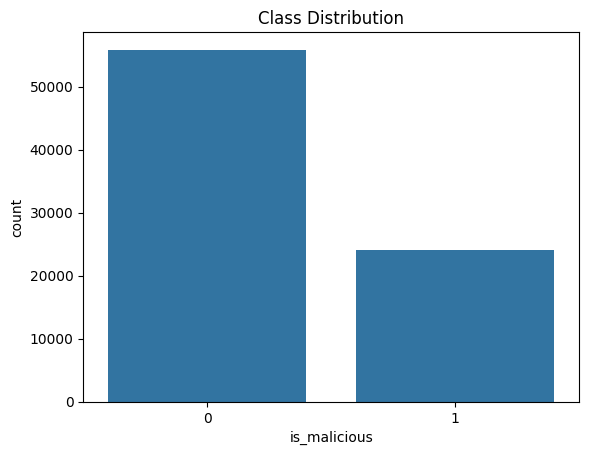

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure()
sns.countplot(x='is_malicious', data=df)
plt.title("Class Distribution")
plt.show()

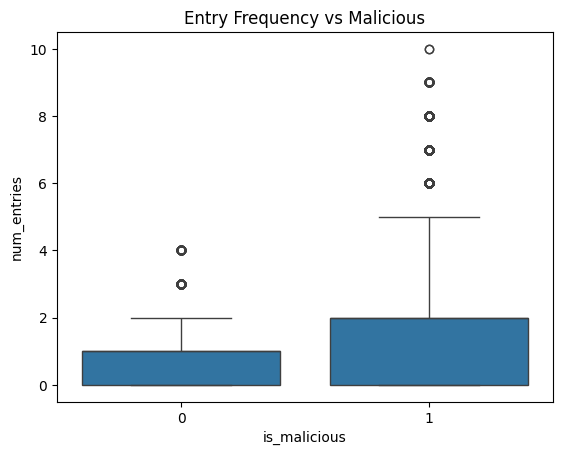

In [15]:
plt.figure()
sns.boxplot(x='is_malicious', y='num_entries', data=df)
plt.title("Entry Frequency vs Malicious")
plt.show()

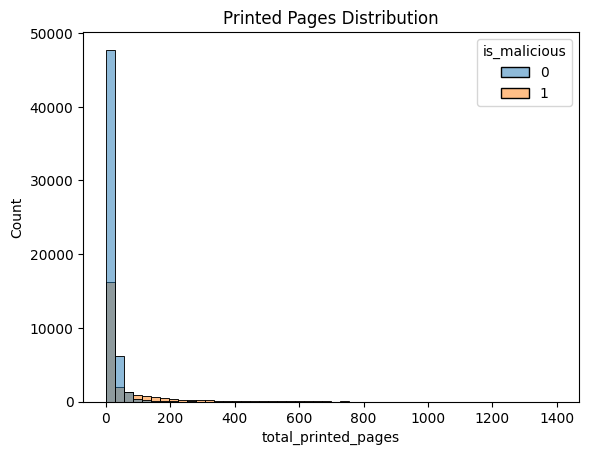

In [16]:
plt.figure()
sns.histplot(data=df, x='total_printed_pages', hue='is_malicious', bins=50)
plt.title("Printed Pages Distribution")
plt.show()